# Week 6: Grounded answers with citations, refusal and answer language

Runs on the project in `src/`. Experiment results are read from `results/` (regenerate with `python eval/evaluate_week6.py`).

In [1]:
import sys, json, pathlib
import pandas as pd
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import torch  # before faiss on macOS
pd.set_option('display.max_colwidth', 120)

## 1. Choosing the LLM (T26)

**Qwen/Qwen3.5-4B** (Apache-2.0, not gated). It runs locally, so questions never leave the machine; the model card lists support for 201 languages and dialects; at 4B parameters (9.3 GB of weights) it fits a Colab T4 in float16. Thinking mode is switched off and decoding is greedy, so the same question always gives the same answer.

In [2]:
import generate
print(generate.__doc__)

Grounded answer generation with an openly licensed LLM (Qwen/Qwen3.5-4B, Apache-2.0).

Why this model (task T26):
  * Apache-2.0 and not gated, so it can be run locally or on a free Colab GPU and user questions
    never leave the machine (see docs/ethics-notes.md: no third-party API without consent).
  * The model card states support for 201 languages and dialects; Polish, Romanian, Arabic and Urdu
    are all needed here.
  * 4B parameters (9.3 GB of weights in 16-bit): fits a 16 GB Colab T4 in float16 and the 24 GB development laptop in bfloat16.
Qwen3.5 "thinks" before answering by default; thinking is switched off (enable_thinking=False) so the
output is the answer only. Decoding is greedy so that every run gives the same answer.



## 2. The grounded prompt (T27)

The three passages from the week 5 search stage are numbered [1] to [3]. The model may use only those facts, must end every sentence with a citation, and must write plain language in the requested language. Titles, links and fetch dates are never written by the model: they are looked up from the citation number.

In [3]:
from generate import build_messages
search = json.loads((ROOT / 'results/week6_search.json').read_text())
example = search['M02-pl']
for m in build_messages('Czy potrzebuję dowodu adresu, żeby zarejestrować się u lekarza rodzinnego?', example['results'], 'pl'):
    print(f"--- {m['role']} ---\n{m['content'][:1500]}\n")

--- system ---
You help people in England understand official guidance on health services, housing and schools.
You are given numbered extracts from official GOV.UK and NHS.uk pages, and a question.

Rules:
1. Use ONLY facts stated in the extracts. Never add facts, dates, places or general remarks from your own knowledge.
2. Every sentence must end with the number of the extract it comes from, in square brackets, for example [1] or [1][2].
   If you cannot point to an extract for a sentence, leave that sentence out.
3. Answer the question first. Write in plain language: short sentences, everyday words, no more than 120 words.
4. If the extracts do not answer the question, reply with exactly NO_ANSWER and nothing else.
5. Do not give medical diagnoses or legal advice about the user's own case; explain what the guidance says.
6. Write the whole answer in Polish.

--- user ---
Extracts:

[1] Register with a GP surgery - What you need to register with a GP surgery
You'll only be asked to g

## 3. The assistant end to end

`src/assistant.py`: search (set-up F) > refusal rule 1 (reranker score below the threshold) > refusal rule 2 (yes/no check: do the passages answer the question?) > answer with citations > refusal rule 3 (model writes NO_ANSWER) > source cards > NHS 111/999 note when an NHS.uk page is cited. Loading the model takes a minute.

In [4]:
from assistant import Assistant
bot = Assistant()

def ask(q):
    a = bot.ask(q)
    print(f"Q [{a['lang']}] {q}\n  top reranker score {a['top_score']:.3f}  refused={a['refused']} {a['reason'] or ''}\n")
    print(a['answer'])
    for s in a['sources']:
        print(f"  [{s['n']}] {s['title']} > {s['heading']}\n      {s['url']}  (fetched {s['fetched_at'][:10]})")
    print('\n' + '=' * 80 + '\n')

ask('Can I be fined for taking my child on holiday during term time?')
ask('Czy potrzebuję dowodu adresu, żeby zarejestrować się u lekarza rodzinnego?')
ask('How do I renew my UK passport?')   # not in the corpus: should be refused

W1112 11:35:51.731000 1738 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


... (2 outputs left out)

[transformers] `fused_recurrent_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


Q [en] Can I be fined for taking my child on holiday during term time?
  top reranker score 0.999  refused=False 

Yes, you can be fined. You may face a fine of £80, which rises to £160 if you do not pay within 21 days [3]. From the 2024 to 2025 school year, each parent can receive up to two fines for the same child in a three-year period [3]. If you do not pay the fine within 28 days, you may be taken to court [3]. If your child is off school three or more times in three years, you might not be fined but could still be taken to court [3]. Your local council sets the specific rules on fines and payments [3].
  [3] School attendance and absence > If you get a fine / If you’re taken to court
      https://www.gov.uk/school-attendance-absence  (fetched 2026-10-28)




Q [pl] Czy potrzebuję dowodu adresu, żeby zarejestrować się u lekarza rodzinnego?
  top reranker score 0.789  refused=False 

Nie, nie potrzebujesz dowodu adresu, aby zarejestrować się u lekarza rodzinnego. Wymagane są tylko podstawowe dane, takie jak imię, data urodzenia i adres. Nie trzeba dostarczać dowodu na adres ani dowodu na status imigracyjny. Jeśli nie masz stałego adresu, możesz użyć adresu tymczasowego lub adresu gabinetu lekarskiego [1]. Dla dzieci poniżej 16 lat rodzic lub opiekun musi dostarczyć dowód tożsamości i adresu dziecka, ale nie jest to wymagane dla samej rejestracji dorosłego [2].

Jeśli potrzebujesz pilnej pomocy medycznej, zadzwoń pod numer 111. W nagłym wypadku dzwoń pod 999.
  [1] Register with a GP surgery > What you need to register with a GP surgery
      https://www.nhs.uk/nhs-services/gps/how-to-register-with-a-gp-surgery/  (fetched 2026-10-28)
  [2] Register with a GP surgery > Changing your address with your current GP surgery / Registering a baby or 

Q [en] How do I renew my UK passport?
  top reranker score 0.005  refused=True low relevance

I could not find an answer to this in the official GOV.UK and NHS pages I use. Please check GOV.UK or NHS.uk, or contact your local council.




## 4. Refusal rule 1: the relevance threshold (T28)

50 unanswerable questions (`eval/unanswerable.csv`: 10 topics not in the 38 pages x 5 languages) were added to the 150 answerable ones. The threshold is 0.9 x the lowest top reranker score of any answerable question whose answer passage was retrieved, so no retrievable answer is refused at this step.

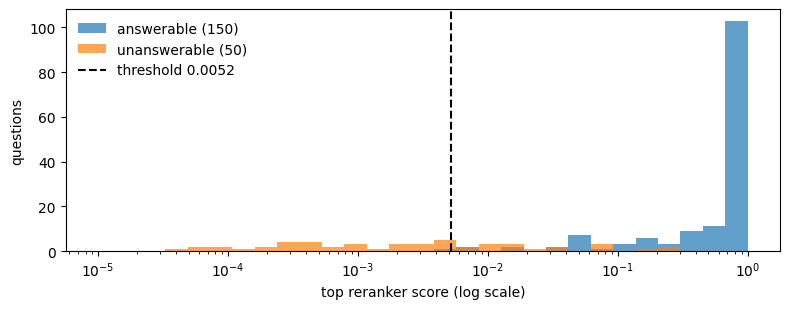

,min,50%,max
answerable,,,
False,0.000,0.003,0.294
True,0.005,0.919,0.999


In [5]:
import numpy as np, matplotlib.pyplot as plt
qs = pd.concat([pd.read_csv(ROOT / 'eval/queries.csv').assign(answerable=True),
                pd.read_csv(ROOT / 'eval/unanswerable.csv').assign(answerable=False)])
qs['top_score'] = [search[f'{r.qid}-{r.lang}']['results'][0]['score'] for r in qs.itertuples()]
from assistant import THRESHOLD
bins = np.logspace(-5, 0, 30)
plt.figure(figsize=(8, 3.2))
plt.hist(qs[qs.answerable].top_score, bins=bins, alpha=0.7, label='answerable (150)')
plt.hist(qs[~qs.answerable].top_score, bins=bins, alpha=0.7, label='unanswerable (50)')
plt.axvline(THRESHOLD, color='k', ls='--', label=f'threshold {THRESHOLD}')
plt.xscale('log'); plt.xlabel('top reranker score (log scale)'); plt.ylabel('questions'); plt.legend(frameon=False)
plt.tight_layout(); plt.show()
qs.groupby('answerable').top_score.describe()[['min', '50%', 'max']].round(3)

## 5. Refusal rule 2: why a separate yes/no check was added

In the first run (v1) the model was told to write NO_ANSWER when the passages do not answer the question. For 17 of the 18 unanswerable questions that passed the threshold it did not: it explained in a sentence that the extracts do not cover the topic. The fix is a separate, short yes/no call before the answer is written.

In [6]:
ans = pd.read_csv(ROOT / 'results/week6_answers.csv')
soft = ans[(~ans.answerable) & (ans['mode'] == 'direct') & (ans.reason != 'low relevance')]
soft[['qid', 'lang', 'top_score', 'check_yes', 'answer']].head(8)

,qid,lang,top_score,check_yes,answer
153,U01,ar,0.011358,False,لا تحتوي المستندات على معلومات عن كيفية تجديد جواز السفر البريطاني.
155,U02,en,0.029441,False,"I could not find an answer to this in the official GOV.UK and NHS pages I use. Please check GOV.UK or NHS.uk, or con..."
158,U02,ar,0.018553,False,لا توجد معلومات في المستندات حول الحد الأدنى للأجور لشخص عمره 21 عامًا. [1][2][3]\n\nإذا كنت بحاجة إلى مساعدة طبية ا...
159,U02,ur,0.009006,True,دی گئی معلومات میں 21 سال کے شخص کی کم از کم اجرت کا ذکر نہیں ہے۔ [1][2][3]\n\nاگر آپ کو ابھی طبی مدد کی ضرورت ہے تو...
160,U03,en,0.189892,False,The provided extracts do not contain information on how to apply for British citizenship. They only explain how to p...
161,U03,pl,0.021901,False,Podane wyrywy nie zawierają informacji o ubieganiu się o brytyjskie obywatelstwo. Opisują one jedynie opłacanie opła...
162,U03,ro,0.086364,False,Nu există informații în extrasele furnizate despre cum se aplică pentru cetățenia britanică. Textul se referă doar l...
163,U03,ar,0.080416,False,لا تحتوي المستندات على معلومات عن كيفية التقدم بطلب للحصول على الجنسية البريطانية. [4]


In [7]:
ref = pd.read_csv(ROOT / 'results/week6_refusal.csv')
ref[ref['mode'] == 'direct'].pivot_table(index=['answerable', 'reason'], columns='version', values='n', dropna=False).fillna(0).astype(int)

version                           final   v1
answerable reason                           
False      check: not in sources     10    0
           low relevance             32   32
           model: not in sources      1    1
           nan                        7   17
True       check: not in sources      0    0
           low relevance              0    0
           model: not in sources      0    0
           nan                      150  150

## 6. Experiment: answer in the user's language - direct vs translate (T29)

* **direct**: the LLM writes in the user's language.
* **translate**: the LLM writes in English and NLLB translates each sentence (citations taken out and put back).

The first translate run was invalid: the model kept writing in the question's language (94-100% of drafts) despite being told to write English, so the instruction is now repeated after the question. That run is kept in `results/week6_answers_v1.csv`.

Automatic checks on each answer: **cited** = has valid [n] citations; **cites_answer** = a cited passage contains the question's verbatim answer phrase; **lang_ok** = written in the question's language; **refused_unanswerable** = share of the 50 unanswerable questions refused. These check form and grounding, not factual accuracy (scored by hand in week 7).

In [8]:
by = pd.read_csv(ROOT / 'results/week6_by_mode.csv')
by[by.version == 'final'].drop(columns='version').set_index(['mode', 'lang'])

n_answerable  answered  cited  cites_answer  lang_ok  \
mode      lang                                                         
direct    ALL            150       1.0  0.960         0.833      1.0   
          en              30       1.0  0.933         0.800      1.0   
          pl              30       1.0  0.967         0.833      1.0   
          ro              30       1.0  1.000         0.867      1.0   
          ar              30       1.0  0.967         0.833      1.0   
          ur              30       1.0  0.933         0.833      1.0   
translate ALL            120       1.0  0.933         0.808      1.0   
          pl              30       1.0  0.967         0.833      1.0   
          ro              30       1.0  0.900         0.767      1.0   
          ar              30       1.0  0.933         0.833      1.0   
          ur              30       1.0  0.933         0.800      1.0   

                n_unanswerable  refused_unanswerable  sec_per_answer  
mode      lang                                                        
direct    ALL               50                 0.860            19.1  
          en                10                 1.000            19.1  
          pl                10                 0.900            19.1  
          ro                10                 0.900            19.1  
          ar                10                 0.700            19.1  
          ur                10                 0.800            19.1  
translate ALL               40                 0.825            21.8  
          pl                10                 0.900            21.8  
          ro                10                 0.900            21.8  
          ar                10                 0.700            21.8  
          ur                10                 0.800            21.8

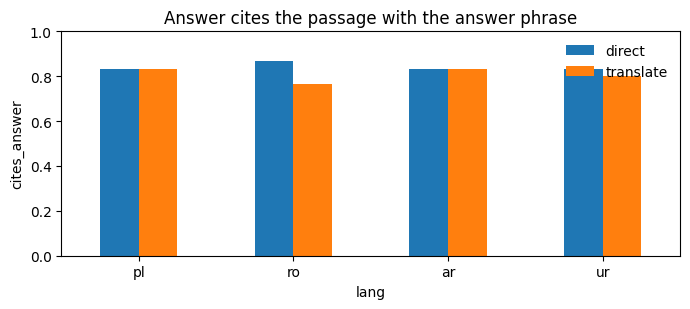

In [9]:
langs = ['pl', 'ro', 'ar', 'ur']
t = by[(by.version == 'final') & by.lang.isin(langs)].pivot_table(index='lang', columns='mode', values='cites_answer').loc[langs]
ax = t.plot.bar(figsize=(7, 3.2), rot=0)
ax.set_ylim(0, 1); ax.set_ylabel('cites_answer'); ax.set_title('Answer cites the passage with the answer phrase')
ax.legend(frameon=False); plt.tight_layout(); plt.show()

### Same question, both modes

Translate mode: NLLB turned *GP surgery* into *chirurgii lekarskiej* (surgery as in an operation) and *eviction* into *wydalenia* (expulsion). (Author's reading of the Polish, not native-checked.)

In [10]:
for qid in ['M02', 'H06']:
    for r in ans[(ans.qid == qid) & (ans.lang == 'pl')].itertuples():
        if r.mode == 'translate':
            print(f'{qid} English draft:\n  {r.raw[:400]}\n')
        print(f'{qid} pl {r.mode}:\n  {r.answer[:400]}\n')

M02 pl direct:
  Nie, nie potrzebujesz potwierdzenia adresu ani statusu imigracyjnego, aby zarejestrować się u lekarza rodzinnego [1]. Wymagane są tylko podstawowe dane, takie jak imię, data urodzenia i adres [1]. Jeśli nie masz stałego adresu, możesz użyć tymczasowego adresu lub adresu gabinetu [1]. Dla dzieci poniżej 16 lat rodzic lub opiekun musi się zarejestrować osobno i może być poproszony o dowód tożsamości

M02 English draft:
  You do not need proof of address or proof of immigration status to register with a GP surgery [1]. You only need to provide basic information such as your name, date of birth, and address [1]. Having an NHS number can make it easier to find your medical records, but you do not need one to register [1]. If you do not have a permanent address, you can register using a temporary address or the addres

M02 pl translate:
  Nie potrzebujesz dowodu adresowego ani dowodu statusu imigracyjnego, aby zarejestrować się w chirurgii lekarskiej. [1] Musisz podać tylko 

## 7. What still goes wrong

In [11]:
final_left = ans[(~ans.answerable) & (~ans.refused) & (ans.check_yes == True) & (ans['mode'] == 'direct')]
print(len(final_left), 'unanswerable questions still answered (direct mode)')
final_left[['qid', 'lang', 'question', 'answer']]

7 unanswerable questions still answered (direct mode)


,qid,lang,question,answer
159,U02,ur,21 سال کے شخص کے لیے کم از کم اجرت کتنی ہے؟,دی گئی معلومات میں 21 سال کے شخص کی کم از کم اجرت کا ذکر نہیں ہے۔ [1][2][3]\n\nاگر آپ کو ابھی طبی مدد کی ضرورت ہے تو...
166,U04,pl,Jak zarejestrować urodzenie mojego dziecka?,Wyciągi nie zawierają informacji o rejestracji urodzenia dziecka. Opisują one jedynie rejestrację dziecka w gabineti...
167,U04,ro,Cum înregistrez nașterea copilului meu?,Nu există informații în extrasele furnizate despre cum se înregistrează nașterea unui copil. Extrasele explică doar ...
168,U04,ar,كيف أسجل ولادة طفلي؟,لا توجد إرشادات في المستندات حول كيفية تسجيل ولادة طفلي.
169,U04,ur,میں اپنے بچے کی پیدائش کا اندراج کیسے کرواؤں؟,اس معلومات میں بچے کی پیدائش کا اندراج کرنے کا طریقہ نہیں دیا گیا ہے۔ [1]\n\nاگر آپ کو ابھی طبی مدد کی ضرورت ہے تو 1...
178,U06,ar,كيف أحصل على قرض عقاري لشراء أول منزل لي؟,لا تحتوي المستندات على معلومات حول كيفية الحصول على قرض عقاري لشراء أول منزل. [2]
198,U10,ar,هل يمكنني الحصول على تذكرة حافلة مجانية لأن عمري أكثر من 60 عامًا؟,لا تذكر المستندات ما إذا كان العمور أكثر من 60 عامًا يمنحك تذكرة حافلة مجانية. [1]


## Findings

* **No answerable question was refused** (0 of 150) by the threshold or the yes/no check.
* **Refusal of unanswerable questions: 33 of 50 in v1, 43 of 50 with the yes/no check** (direct mode). All 7 remaining cases are answers that say in prose that the sources do not cover it; none invents an answer, but they are not clean refusals. Four are 'register a birth' in pl/ro/ar/ur, where GP-registration passages look related.
* **Direct and translate are close** on the 120 non-English questions: 116 vs 112 cited, 101 vs 97 citing the answer passage - about one question per language. NLLB mistranslates key housing and health terms in otherwise correct answers.
* The first translate run was invalid (the model ignored 'write in English'); fixed and rerun.
* All answers were in the question's language in both modes (lingua).
* Decision: use **direct** mode with refusal rules 1-3 (simpler, no NLLB term errors); week 7 hand-scores a sample of both.

## Next (week 7)
Hand-score answer accuracy and faithfulness with a rubric on a gold set, compare against a no-retrieval baseline, and use held-out questions to check the refusal threshold.